In [1]:
import sys
import torch

print("GPU:", torch.cuda.get_device_name(0))
print(
    "Видеопамять:",
    round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 1),
    "ГиБ",
)

GPU: NVIDIA GeForce RTX 4060
Видеопамять: 8.0 ГиБ


In [7]:
import os
import json
import uuid
import transformers
import matplotlib.pyplot as plt
import diffusers

from pathlib import Path
from datetime import datetime
from diffusers import StableDiffusionPipeline
from diffusers import DDIMScheduler
from IPython.display import display
from huggingface_hub import HfApi

PROJECT = Path(r"./")
CACHE = PROJECT / "hf-cache"
OUTPUT = PROJECT / "outputs" / "experiment_001"

CACHE.mkdir(parents=True, exist_ok=True)
OUTPUT.mkdir(parents=True, exist_ok=True)

os.environ["HF_HOME"] = str(CACHE)

In [8]:
pipe = StableDiffusionPipeline.from_pretrained(
    "sd2-community/stable-diffusion-2-1",
    cache_dir=str(PROJECT / "hf-cache" / "hub"),
    torch_dtype=torch.float16,
    use_safetensors=True,
)

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

In [9]:
pipe.enable_model_cpu_offload()

print("Scheduler:", type(pipe.scheduler).__name__)
print("Тип предсказания:", pipe.scheduler.config.prediction_type)

Scheduler: DDIMScheduler
Тип предсказания: v_prediction


In [10]:
def run_experiment(
    pipe,
    prompt=(
        "A photograph of a wooden house beside a mountain lake, "
        "morning light, realistic, detailed"
    ),
    negative_prompt="",
    seed=42,
    steps=30,
    guidance=7.5,
    height=768,
    width=768,
    layer_name="conv_in",
    channels=tuple(range(8)),
    capture_steps=(1, 6, 12, 18, 24, 30),
    all_layers_step=30,
    all_layers_channels=8,  # None — все каналы
    save=False,
    output_dir="./experiments",
    show=True,
    hooks=None
):
    if guidance <= 1:
        raise ValueError("Функция рассчитана на одно изображение с CFG > 1.")

    if steps < 1:
        raise ValueError("steps должен быть положительным.")

    if height % pipe.vae_scale_factor or width % pipe.vae_scale_factor:
        raise ValueError("Размеры должны быть кратны pipe.vae_scale_factor.")

    capture_steps = set(capture_steps)
    if any(step < 1 or step > steps for step in capture_steps):
        raise ValueError("capture_steps должны находиться в диапазоне 1..steps.")

    if all_layers_step is not None and not 1 <= all_layers_step <= steps:
        raise ValueError("all_layers_step должен находиться в диапазоне 1..steps.")

    if all_layers_channels is not None and all_layers_channels < 1:
        raise ValueError("all_layers_channels должен быть > 0 или None.")

    channels = None if channels is None else list(channels)
    if channels is not None and (
        not channels or any(channel < 0 for channel in channels)
    ):
        raise ValueError("channels должен содержать неотрицательные индексы.")

    layer = pipe.unet.get_submodule(layer_name)
    pipe.scheduler = DDIMScheduler.from_config(pipe.scheduler.config)

    device = pipe._execution_device

    activations = {}
    all_activations = {}
    trajectory = {}
    state = {"step": 1}
    handles = []

    def capture_features(module, inputs, output):
        step = state["step"]

        if step not in capture_steps:
            return

        if (
            not isinstance(output, torch.Tensor)
            or output.ndim != 4
            or output.shape[0] != 2
        ):
            raise ValueError(
                f"{layer_name}: ожидался тензор формы [2, C, H, W]."
            )

        if channels is not None and max(channels) >= output.shape[1]:
            raise ValueError(
                f"{layer_name}: доступно {output.shape[1]} каналов."
            )

        selected = output[1] if channels is None else output[1, channels]

        activations[step] = (
            selected.detach().cpu().float().clone()
        )

    def capture_layer(name):
        def hook(module, inputs, output):
            if state["step"] != all_layers_step:
                return

            if not isinstance(output, torch.Tensor) or output.ndim != 4:
                return

            if output.shape[0] != 2:
                raise RuntimeError(
                    f"{name}: ожидался batch=2, получен {output.shape[0]}."
                )

            selected = output[1]

            if all_layers_channels is not None:
                selected = selected[:all_layers_channels]

            # Учитываем повторные вызовы одного модуля.
            all_activations.setdefault(name, []).append(
                selected.detach().cpu().float().clone()
            )

        return hook

    def capture_latents(pipeline, step_index, timestep, callback_kwargs):
        step = step_index + 1

        trajectory[step] = {
            "t_from": int(timestep.item())
            if isinstance(timestep, torch.Tensor)
            else int(timestep),
            "latents_after": (
                callback_kwargs["latents"].detach().cpu().clone()
            ),
        }

        state["step"] = step + 1
        return callback_kwargs

    initial_noise = torch.randn(
        (
            1,
            pipe.unet.config.in_channels,
            height // pipe.vae_scale_factor,
            width // pipe.vae_scale_factor,
        ),
        generator=torch.Generator(device="cpu").manual_seed(seed),
        dtype=torch.float32,
    )

    try:
    # Пользовательские вмешательства.
        if hooks is not None:
            for name, hook_fn in hooks.items():
                module = pipe.unet.get_submodule(name)
                handles.append(
                    module.register_forward_hook(hook_fn)
                )
    
        # Запись активаций выбранного слоя.
        handles.append(
            layer.register_forward_hook(capture_features)
        )
    
        # Запись пространственных выходов конечных модулей.
        if all_layers_step is not None:
            for name, module in pipe.unet.named_modules():
                if name and not any(module.children()):
                    handles.append(
                        module.register_forward_hook(capture_layer(name))
                    )
    
        # Единственный запуск генерации.
        with torch.inference_mode():
            result = pipe(
                prompt=prompt,
                negative_prompt=negative_prompt,
                width=width,
                height=height,
                num_images_per_prompt=1,
                num_inference_steps=steps,
                guidance_scale=guidance,
                eta=0.0,
                latents=initial_noise.to(
                    device=device,
                    dtype=pipe.unet.dtype,
                ).clone(),
                callback_on_step_end=capture_latents,
                callback_on_step_end_tensor_inputs=["latents"],
            )

    finally:
        for handle in handles:
            handle.remove()

        pipe.maybe_free_model_hooks()

    metadata = {
        "model": str(getattr(pipe.config, "_name_or_path", "unknown")),
        "prompt": prompt,
        "negative_prompt": negative_prompt,
        "seed": seed,
        "steps": steps,
        "guidance_scale": guidance,
        "eta": 0.0,
        "height": height,
        "width": width,
        "layer": layer_name,
        "channels": channels,
        "activation_steps": sorted(capture_steps),
        "activation_branch": "conditional",
        "all_layers_step": all_layers_step,
        "all_layers_channels": all_layers_channels,
        "unet_dtype": str(pipe.unet.dtype),
        "scheduler": type(pipe.scheduler).__name__,
        "scheduler_config": dict(pipe.scheduler.config),
        "torch": str(torch.__version__),
        "diffusers": diffusers.__version__,
        "transformers": transformers.__version__,
        "device": str(device),
        "gpu": (
            torch.cuda.get_device_name(device)
            if torch.device(device).type == "cuda"
            else None
        ),
    }

    data = {
        "initial_noise": initial_noise,
        "init_noise_sigma": float(pipe.scheduler.init_noise_sigma),
        "timesteps": pipe.scheduler.timesteps.detach().cpu().clone(),
        "trajectory": trajectory,
        "activations": activations,
        "all_activations": all_activations,
    }

    RUN = None

    if save:
        run_id = (
            datetime.now().strftime("%Y%m%d_%H%M%S")
            + "_"
            + uuid.uuid4().hex[:6]
        )
        RUN = Path(output_dir) / run_id
        RUN.mkdir(parents=True, exist_ok=False)

        torch.save(data, RUN / "tensors.pt")

        (RUN / "metadata.json").write_text(
            json.dumps(metadata, ensure_ascii=False, indent=2, default=str),
            encoding="utf-8",
        )

        result.images[0].save(RUN / "final.png")
        print("Эксперимент сохранён:", RUN)

    if show:
        display(result.images[0])

    print("Латентных состояний:", len(trajectory))
    print("Снимков выбранного слоя:", len(activations))
    print("Модулей с пространственными выходами:", len(all_activations))

    return {
        "result": result,
        "data": data,
        "metadata": metadata,
        "RUN": RUN,
    }

  0%|          | 0/30 [00:00<?, ?it/s]

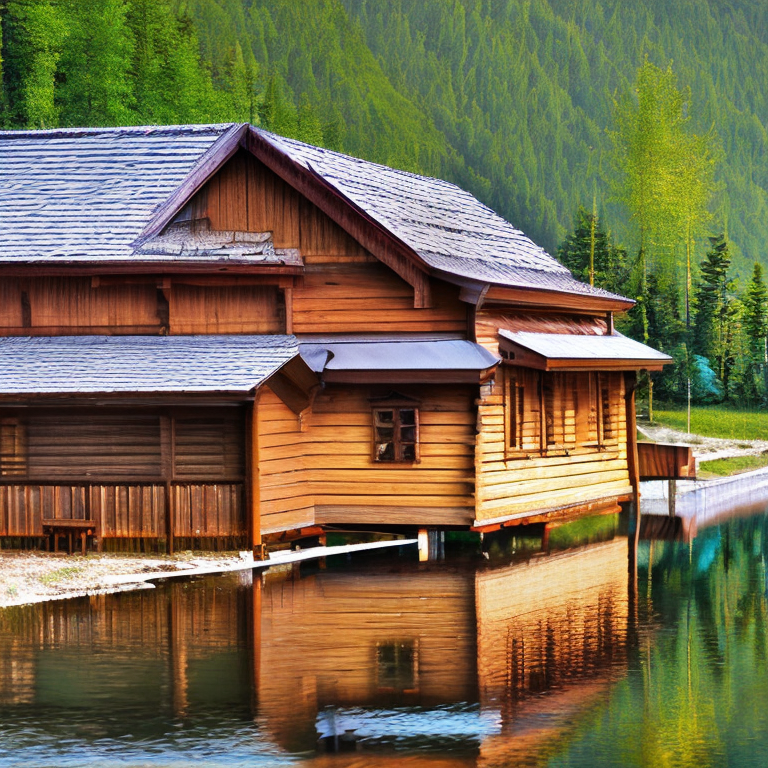

Латентных состояний: 30
Снимков выбранного слоя: 6
Модулей с пространственными выходами: 172


In [11]:
experiment = run_experiment(pipe)

In [13]:
def plot_denoising(
    pipe,
    experiment,
    steps=(1, 6, 12, 18, 24, 30),
    save_path=None,
):
    trajectory = experiment["data"]["trajectory"]
    steps = list(steps)

    if not steps:
        raise ValueError("Укажите хотя бы один шаг.")

    missing = [step for step in steps if step not in trajectory]
    if missing:
        raise ValueError(f"В trajectory отсутствуют шаги: {missing}")

    device = pipe._execution_device

    fig, axes = plt.subplots(
        1,
        len(steps),
        figsize=(3 * len(steps), 3.5),
        squeeze=False,
        layout="constrained",
    )

    images = {}

    try:
        with torch.inference_mode():
            for col, step in enumerate(steps):
                z = trajectory[step]["latents_after"].to(
                    device=device,
                    dtype=pipe.vae.dtype,
                )

                pixels = pipe.vae.decode(
                    z / pipe.vae.config.scaling_factor,
                    return_dict=False,
                )[0]

                image = pipe.image_processor.postprocess(
                    pixels,
                    output_type="pil",
                )[0]

                images[step] = image

                axes[0, col].imshow(image)
                axes[0, col].set_title(f"После шага {step}")
                axes[0, col].set_axis_off()

                del z, pixels

        fig.suptitle("Декодированные латенты по ходу генерации")

        if save_path is not None:
            save_path = Path(save_path)
            save_path.parent.mkdir(parents=True, exist_ok=True)
            fig.savefig(save_path, dpi=150)

        plt.show()

    finally:
        plt.close(fig)
        pipe.maybe_free_model_hooks()

    return images

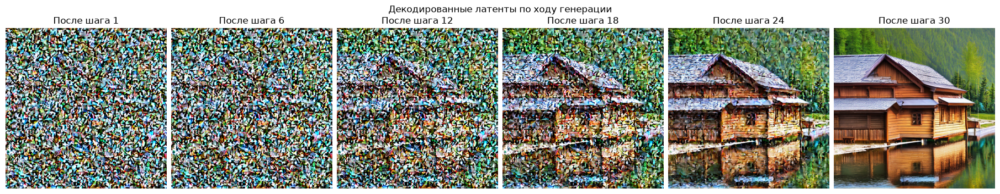

In [14]:
images = plot_denoising(
    pipe,
    experiment,
    steps=[1, 6, 12, 18, 24, 30],
)

In [16]:
def plot_activations(
    experiment,
    steps=None,
    channels=None,
    save_path=None,
):

    activations = experiment["data"]["activations"]
    metadata = experiment["metadata"]

    if not activations:
        raise ValueError("В эксперименте нет сохранённых активаций.")

    steps = sorted(activations) if steps is None else list(steps)

    if not steps:
        raise ValueError("Укажите хотя бы один шаг.")

    missing_steps = [step for step in steps if step not in activations]
    if missing_steps:
        raise ValueError(f"Не сохранены шаги: {missing_steps}")

    # Позиция в тензоре может отличаться от исходного номера канала.
    saved_channels = metadata["channels"]

    if saved_channels is None:
        saved_channels = list(range(activations[steps[0]].shape[0]))
    else:
        saved_channels = list(saved_channels)

    channels = saved_channels if channels is None else list(channels)

    if not channels:
        raise ValueError("Укажите хотя бы один канал.")

    channel_positions = {
        channel: index
        for index, channel in enumerate(saved_channels)
    }

    missing_channels = [
        channel for channel in channels
        if channel not in channel_positions
    ]
    if missing_channels:
        raise ValueError(f"Не сохранены каналы: {missing_channels}")

    fig, axes = plt.subplots(
        len(steps),
        len(channels),
        figsize=(2.5 * len(channels), 2.5 * len(steps)),
        squeeze=False,
        layout="constrained",
    )

    try:
        for col, channel in enumerate(channels):
            index = channel_positions[channel]

            # Общая шкала для одного канала на всех выбранных шагах.
            limit = max(
                max(
                    activations[step][index].abs().max().item()
                    for step in steps
                ),
                1e-8,
            )

            for row, step in enumerate(steps):
                ax = axes[row, col]

                im = ax.imshow(
                    activations[step][index].detach().float().cpu().numpy(),
                    cmap="RdBu_r",
                    vmin=-limit,
                    vmax=limit,
                    interpolation="nearest",
                )

                ax.set_xticks([])
                ax.set_yticks([])

                if row == 0:
                    ax.set_title(f"Канал {channel}")

                if col == 0:
                    ax.set_ylabel(f"Шаг {step}")

            fig.colorbar(
                im,
                ax=axes[:, col].tolist(),
                orientation="horizontal",
                shrink=0.8,
                pad=0.03,
                label="Отклик",
            )

        fig.suptitle(
            f"Выход слоя {metadata['layer']} — условная ветвь"
        )

        if save_path is not None:
            save_path = Path(save_path)
            save_path.parent.mkdir(parents=True, exist_ok=True)
            fig.savefig(save_path, dpi=150)

        plt.show()

    finally:
        plt.close(fig)

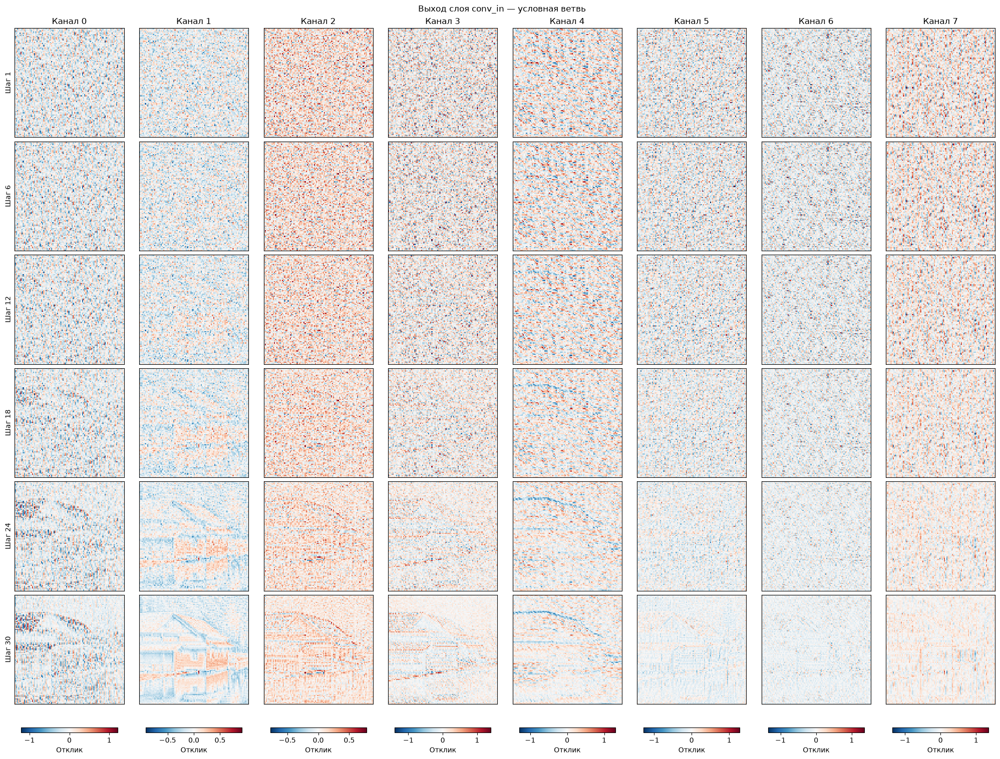

In [17]:
plot_activations(experiment)

In [20]:
print(experiment.keys())
print(experiment["data"].keys())

dict_keys(['result', 'data', 'metadata', 'RUN'])
dict_keys(['initial_noise', 'init_noise_sigma', 'timesteps', 'trajectory', 'activations', 'all_activations'])


## Карты активации CNN
- conv_in
- down_blocks
- mid_blocks
- up_blocks
- conv_out

In [21]:
def get_activations(
    layer_name,
    steps,
    channels_per_page=32,
    columns=8,
    save=False,
    call_index=-1,
):
    """
    Использует сохранённую trajectory исходного эксперимента с DDIM.

    Пространственный выход [B, C, H, W]:
        показывает все каналы страницами.

    Выход [B, N, D] или [B, D]:
        показывает матрицу или вектор без пространственного reshape.

    Если модуль вызван несколько раз:
        call_index выбирает вызов (-1 — последний).

    Если выход составной:
        берётся первый тензор.
    """
    if channels_per_page < 1 or columns < 1:
        raise ValueError("channels_per_page и columns должны быть > 0.")

    if not isinstance(pipe.scheduler, DDIMScheduler):
        raise ValueError("Этот вариант рассчитан на исходный DDIMScheduler.")

    steps = list(steps)
    activations = {}
    layer = pipe.unet.get_submodule(layer_name)

    # Учитывает также стандартный CPU offload в diffusers.
    device = pipe._execution_device
    dtype = pipe.unet.dtype
    use_cfg = metadata["guidance_scale"] > 1
    branch_index = 1 if use_cfg else 0

    captured = []

    def first_tensor(output):
        if isinstance(output, torch.Tensor):
            return output

        if isinstance(output, dict):
            values = output.values()
        elif isinstance(output, (tuple, list)):
            values = output
        else:
            return None

        for value in values:
            tensor = first_tensor(value)
            if tensor is not None:
                return tensor

        return None

    def capture_features(module, inputs, output):
        output = first_tensor(output)

        if output is None:
            raise ValueError(f"{layer_name}: в выходе не найден тензор.")

        expected_batch = 2 if use_cfg else 1
        if output.ndim < 2 or output.shape[0] != expected_batch:
            raise ValueError(
                f"{layer_name}: выход {tuple(output.shape)} не имеет "
                f"ожидаемую первую ось batch={expected_batch}."
            )

        captured.append(
            output[branch_index].detach().cpu().float().clone()
        )

    handle = None

    try:
        with torch.inference_mode():
            prompt_embeds, negative_prompt_embeds = pipe.encode_prompt(
                prompt=metadata["prompt"],
                negative_prompt=metadata.get("negative_prompt", ""),
                device=device,
                num_images_per_prompt=1,
                do_classifier_free_guidance=use_cfg,
            )

            if use_cfg:
                prompt_embeds = torch.cat(
                    [negative_prompt_embeds, prompt_embeds],
                    dim=0,
                )

            handle = layer.register_forward_hook(capture_features)

            for step in steps:
                if step not in trajectory:
                    raise ValueError(f"Шаг {step} отсутствует в trajectory.")

                captured.clear()

                if step == 1:
                    z = initial_noise.to(
                        device=device,
                        dtype=dtype,
                    ).clone()
                    z = z * pipe.scheduler.init_noise_sigma
                else:
                    z = trajectory[step - 1]["latents_after"].to(
                        device=device,
                        dtype=dtype,
                    ).clone()

                t = torch.tensor(
                    trajectory[step]["t_from"],
                    device=device,
                    dtype=torch.long,
                )

                if use_cfg:
                    z = torch.cat([z, z], dim=0)

                z = pipe.scheduler.scale_model_input(z, t)

                # Только один проход U-Net:
                # без scheduler.step и без декодирования VAE.
                pipe.unet(
                    z,
                    t,
                    encoder_hidden_states=prompt_embeds,
                    return_dict=False,
                )

                if not captured:
                    raise ValueError(
                        f"Модуль {layer_name} не был вызван."
                    )

                if not -len(captured) <= call_index < len(captured):
                    raise ValueError(
                        f"Модуль вызван {len(captured)} раз; "
                        f"call_index={call_index} недопустим."
                    )

                activations[step] = captured[call_index]

                print(
                    f"{layer_name}, шаг {step}: "
                    f"форма {tuple(activations[step].shape)}, "
                    f"вызовов модуля: {len(captured)}"
                )

    finally:
        if handle is not None:
            handle.remove()

        pipe.maybe_free_model_hooks()

    if not activations:
        return activations

    limit = max(
        max(maps.abs().max().item() for maps in activations.values()),
        1e-8,
    )

    if save:
        RUN.mkdir(parents=True, exist_ok=True)
        torch.save(
            activations,
            RUN / f"{layer_name}_activations.pt",
        )

    for step in steps:
        maps = activations[step]

        # Векторные и последовательностные выходы.
        if maps.ndim in (1, 2):
            matrix = maps.unsqueeze(0) if maps.ndim == 1 else maps

            fig, ax = plt.subplots(
                figsize=(12, 4),
                layout="constrained",
            )

            im = ax.imshow(
                matrix.numpy(),
                cmap="RdBu_r",
                vmin=-limit,
                vmax=limit,
                aspect="auto",
                interpolation="nearest",
            )

            ax.set_title(f"{layer_name} — шаг {step}")
            ax.set_xlabel("Компонента признака")
            ax.set_ylabel(
                "Позиция последовательности"
                if maps.ndim == 2 else "Вектор"
            )
            fig.colorbar(im, ax=ax, label="Отклик")

            if save:
                fig.savefig(
                    RUN / f"{layer_name}_step_{step}.png",
                    dpi=150,
                )

            plt.show()
            plt.close(fig)
            continue

        if maps.ndim != 3:
            print(
                f"Шаг {step}: тензор сохранён в памяти, "
                f"визуализация формы {tuple(maps.shape)} не предусмотрена."
            )
            continue

        # Пространственные выходы [C, H, W].
        channels = list(range(maps.shape[0]))

        for start in range(0, len(channels), channels_per_page):
            page_channels = channels[start:start + channels_per_page]
            rows = (len(page_channels) + columns - 1) // columns

            fig, axes = plt.subplots(
                rows,
                columns,
                figsize=(2.3 * columns, 2.3 * rows),
                squeeze=False,
                layout="constrained",
            )

            for ax in axes.flat:
                ax.set_axis_off()

            for ax, channel in zip(axes.flat, page_channels):
                im = ax.imshow(
                    maps[channel].numpy(),
                    cmap="RdBu_r",
                    vmin=-limit,
                    vmax=limit,
                    interpolation="nearest",
                )
                ax.set_title(f"Канал {channel}", fontsize=10)

            fig.colorbar(
                im,
                ax=axes.ravel().tolist(),
                orientation="horizontal",
                shrink=0.6,
                pad=0.03,
                label="Отклик — общая шкала для каналов и шагов",
            )

            fig.suptitle(
                f"{layer_name} — шаг {step}, условная ветвь\n"
                f"Каналы {page_channels[0]}–{page_channels[-1]}"
            )

            if save:
                fig.savefig(
                    RUN / (
                        f"{layer_name}_step_{step}_"
                        f"channels_{page_channels[0]:03d}_"
                        f"{page_channels[-1]:03d}.png"
                    ),
                    dpi=150,
                )

            plt.show()
            plt.close(fig)

    return activations

#### Conv_in

In [22]:
out_activations = 0
for name, module in pipe.unet.named_modules():
    if name.startswith("conv_in") and isinstance(module, torch.nn.Conv2d):
        print(
            f"{name}: "
            f"каналы {module.in_channels} → {module.out_channels}, "
            f"ядро {module.kernel_size}"
        )
        out_activations += module.out_channels

print(f"\nПо всем сверткам блока тепловых карт активаций: {out_activations}")

conv_in: каналы 4 → 320, ядро (3, 3)

По всем сверткам блока тепловых карт активаций: 320


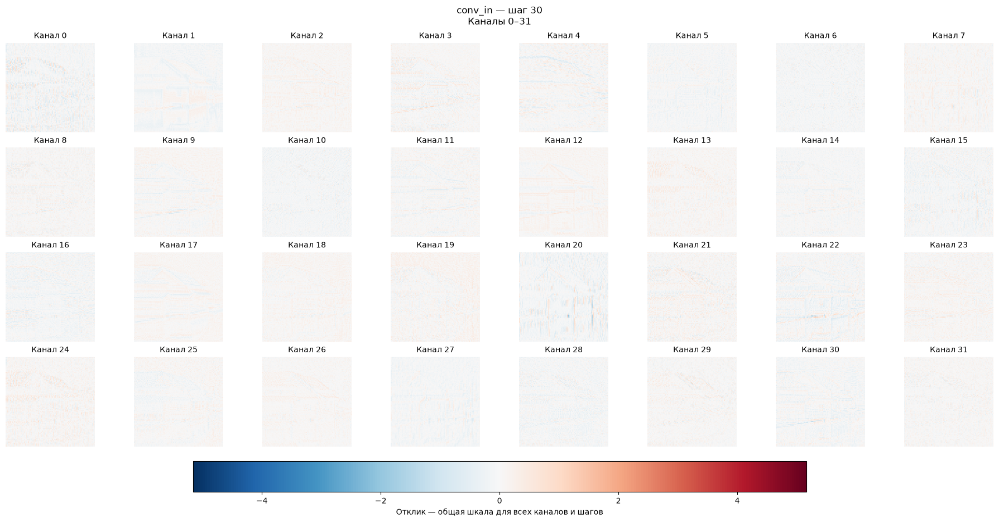

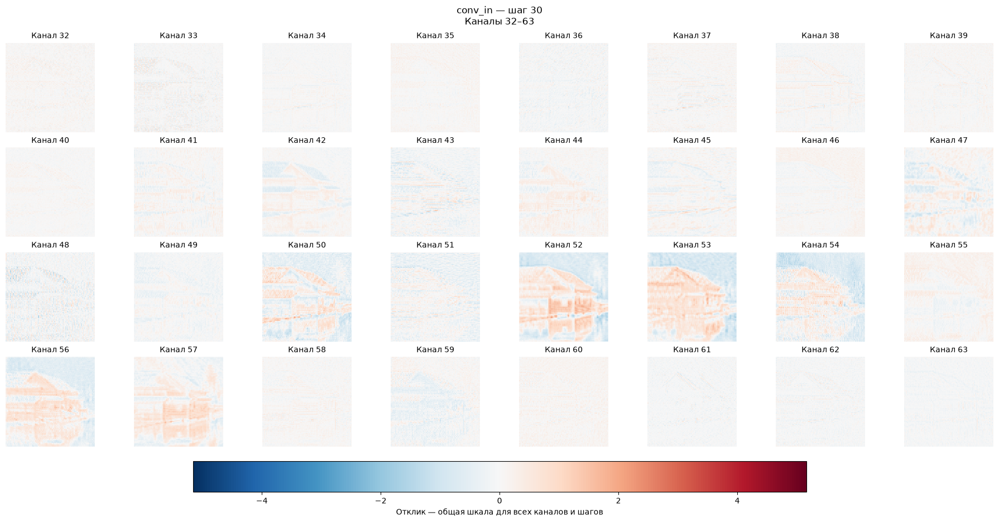

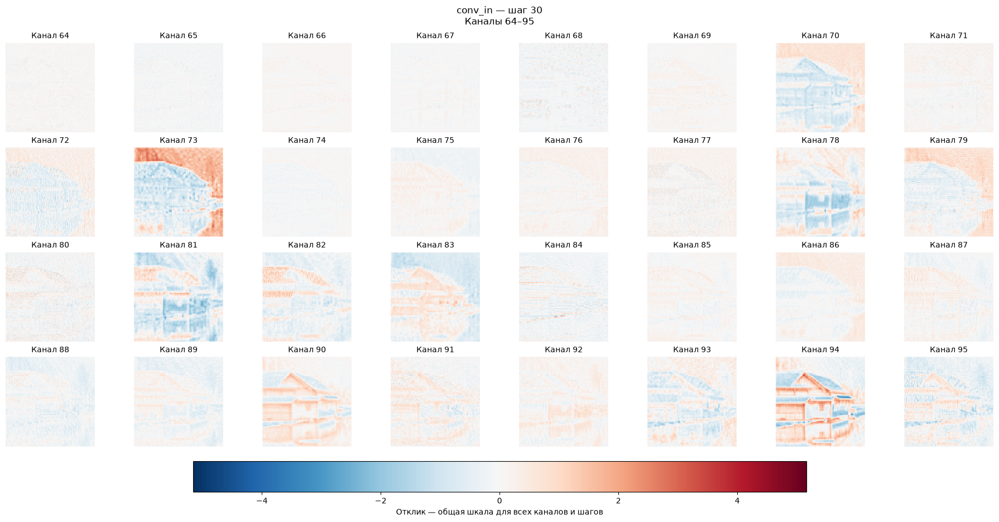

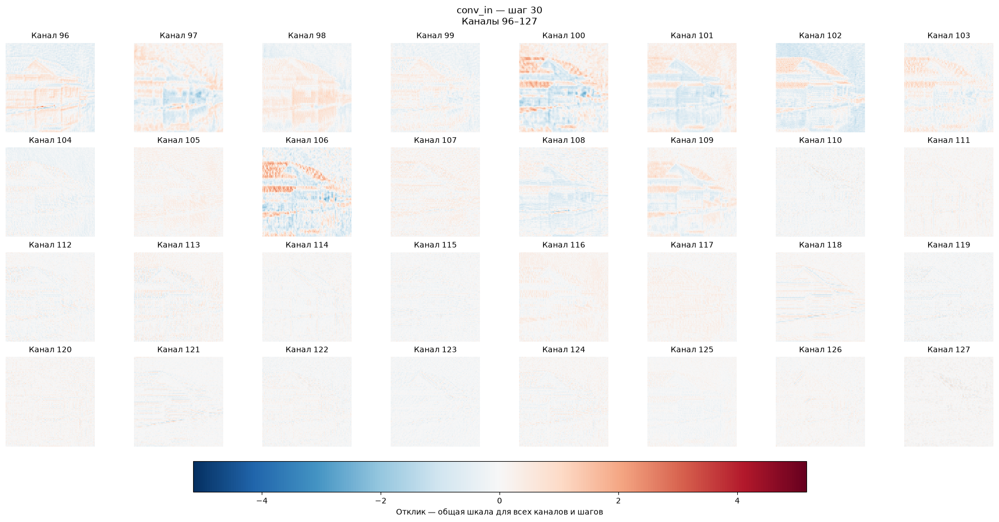

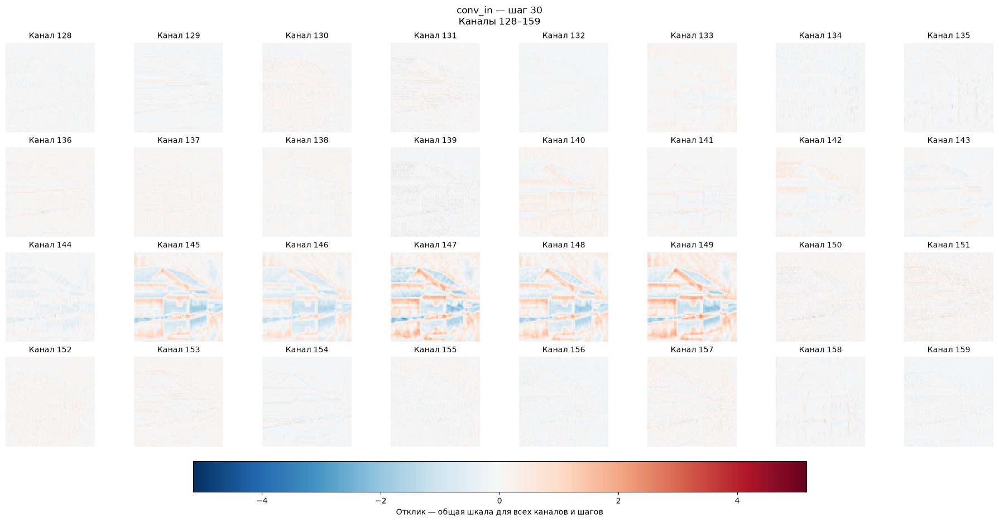

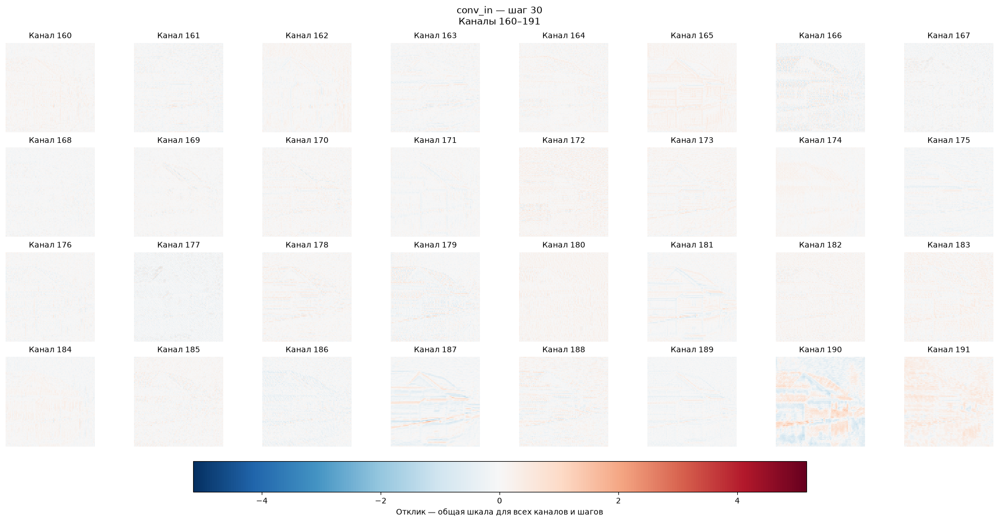

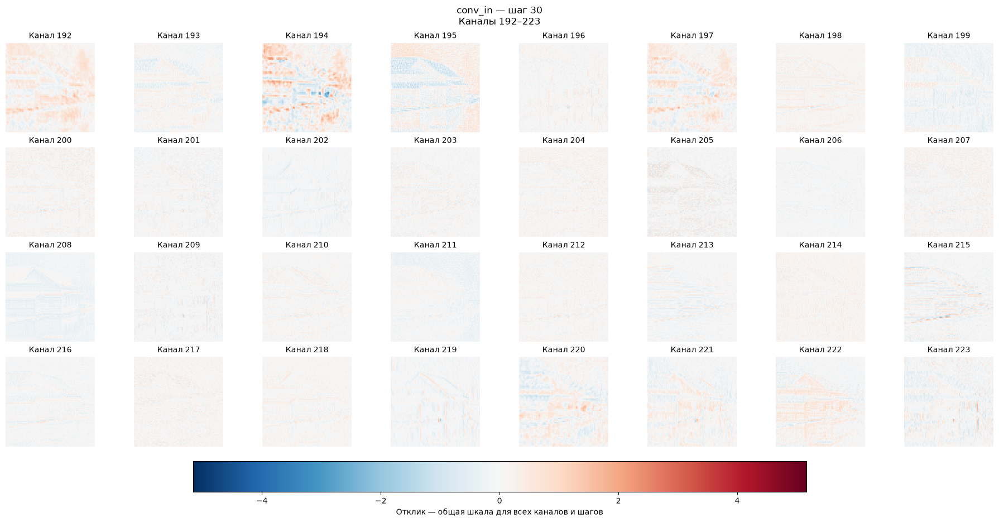

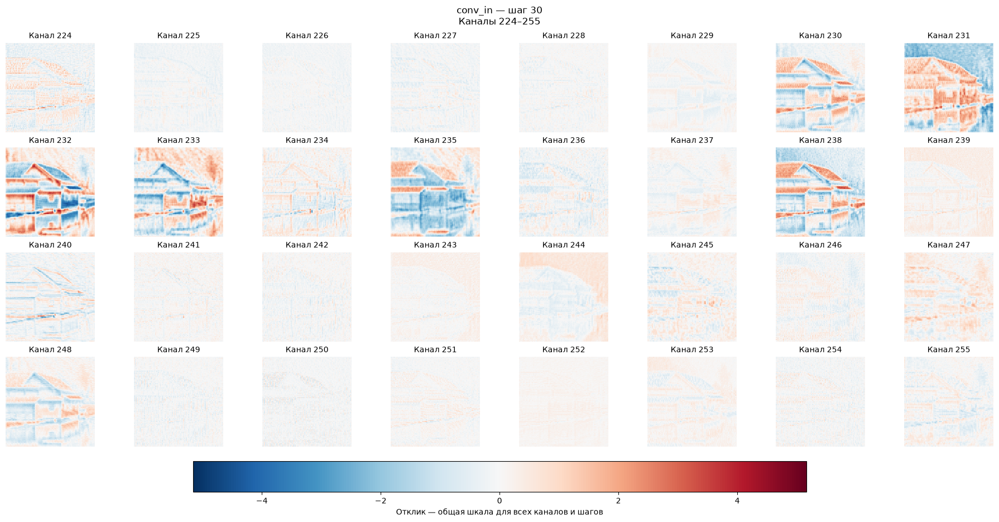

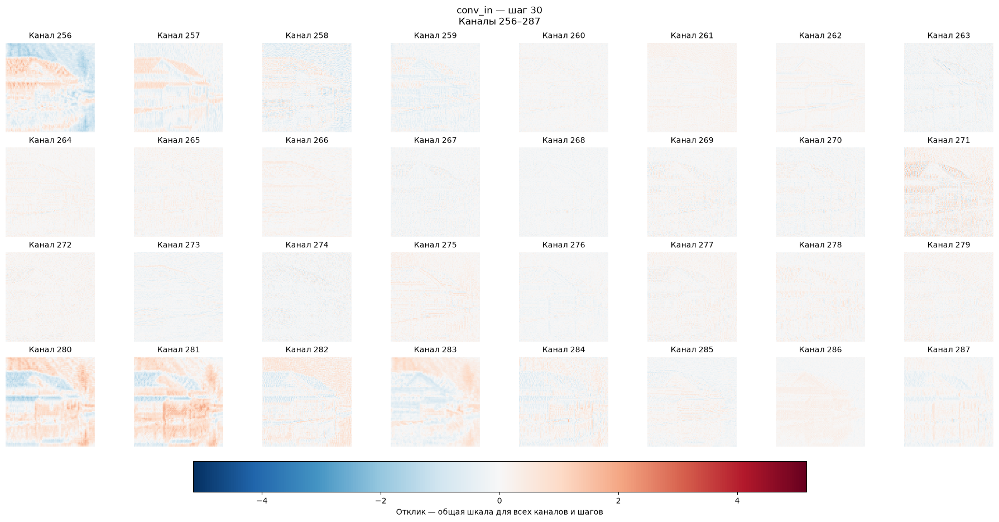

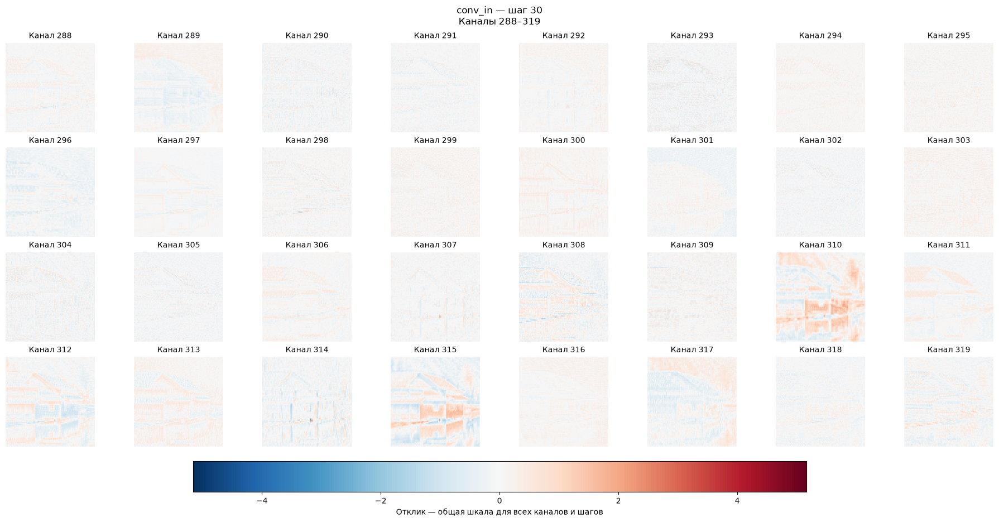

In [37]:
get_activations("conv_in", steps=[30])

### down_blocks

In [56]:
out_activations = 0
for name, module in pipe.unet.named_modules():
    if name.startswith("down_block") and isinstance(module, torch.nn.Conv2d):
        print(
            f"{name}: "
            f"каналы {module.in_channels} → {module.out_channels}, "
            f"ядро {module.kernel_size}"
        )
        out_activations += module.out_channels

print(f"\nПо всем сверткам блока тепловых карт активаций: {out_activations}")

down_blocks.0.resnets.0.conv1: каналы 320 → 320, ядро (3, 3)
down_blocks.0.resnets.0.conv2: каналы 320 → 320, ядро (3, 3)
down_blocks.0.resnets.1.conv1: каналы 320 → 320, ядро (3, 3)
down_blocks.0.resnets.1.conv2: каналы 320 → 320, ядро (3, 3)
down_blocks.0.downsamplers.0.conv: каналы 320 → 320, ядро (3, 3)
down_blocks.1.resnets.0.conv1: каналы 320 → 640, ядро (3, 3)
down_blocks.1.resnets.0.conv2: каналы 640 → 640, ядро (3, 3)
down_blocks.1.resnets.0.conv_shortcut: каналы 320 → 640, ядро (1, 1)
down_blocks.1.resnets.1.conv1: каналы 640 → 640, ядро (3, 3)
down_blocks.1.resnets.1.conv2: каналы 640 → 640, ядро (3, 3)
down_blocks.1.downsamplers.0.conv: каналы 640 → 640, ядро (3, 3)
down_blocks.2.resnets.0.conv1: каналы 640 → 1280, ядро (3, 3)
down_blocks.2.resnets.0.conv2: каналы 1280 → 1280, ядро (3, 3)
down_blocks.2.resnets.0.conv_shortcut: каналы 640 → 1280, ядро (1, 1)
down_blocks.2.resnets.1.conv1: каналы 1280 → 1280, ядро (3, 3)
down_blocks.2.resnets.1.conv2: каналы 1280 → 1280, ядро

down_blocks.1.resnets.1.conv2, шаг 30: форма (640, 48, 48), вызовов модуля: 1


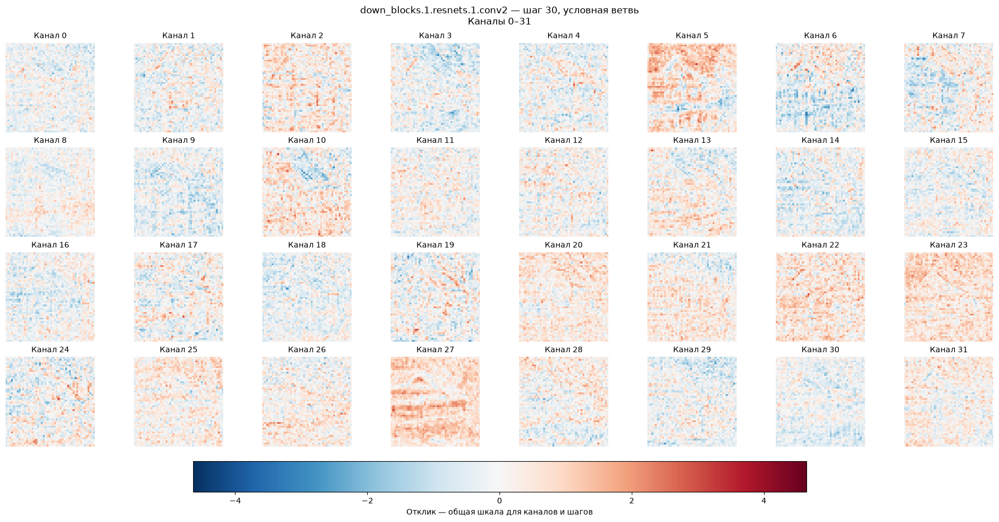

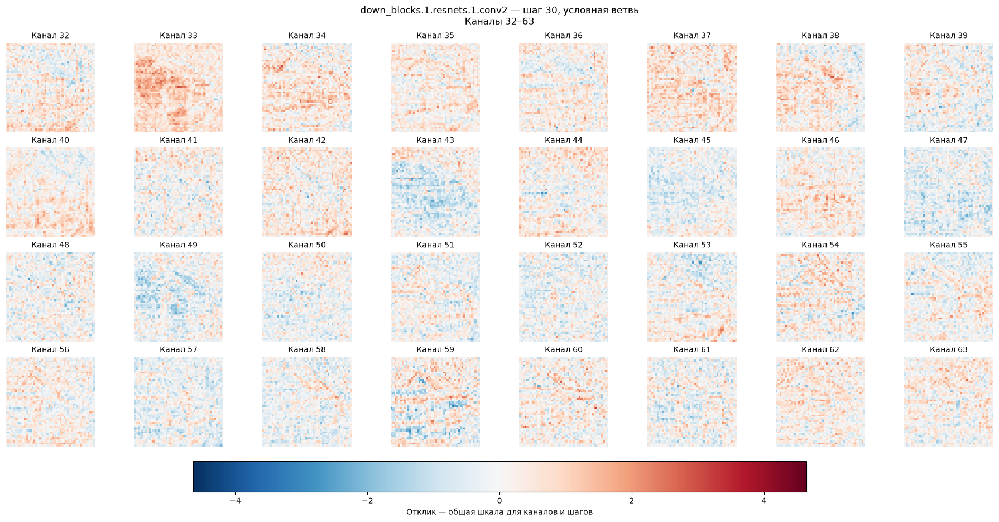

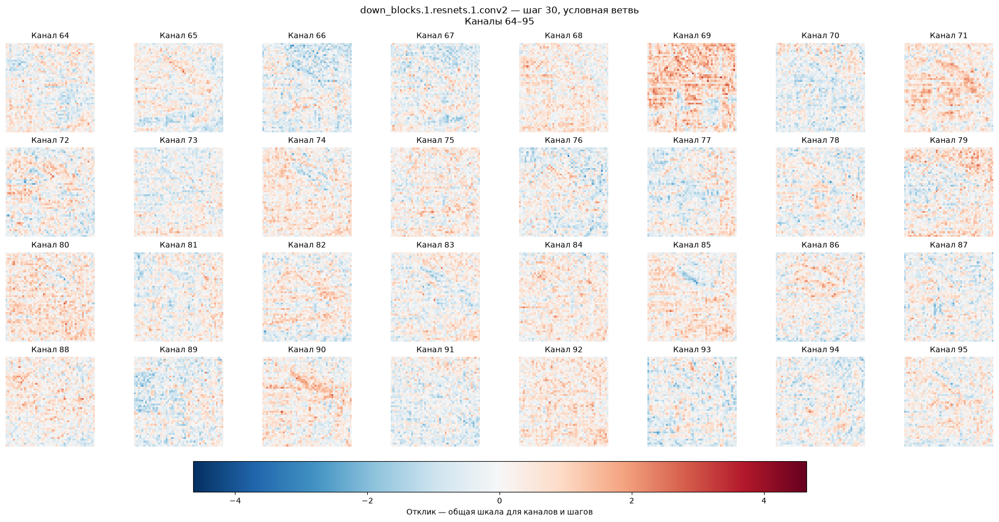

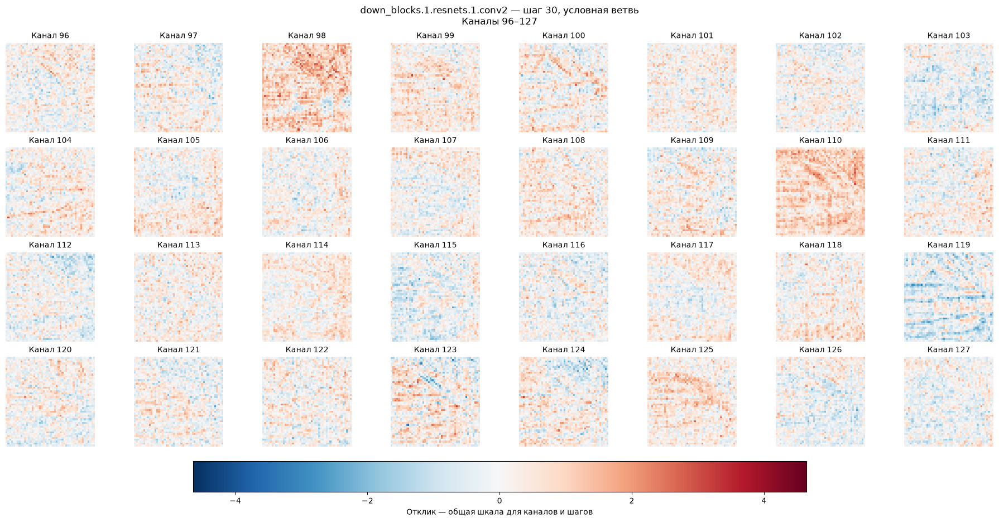

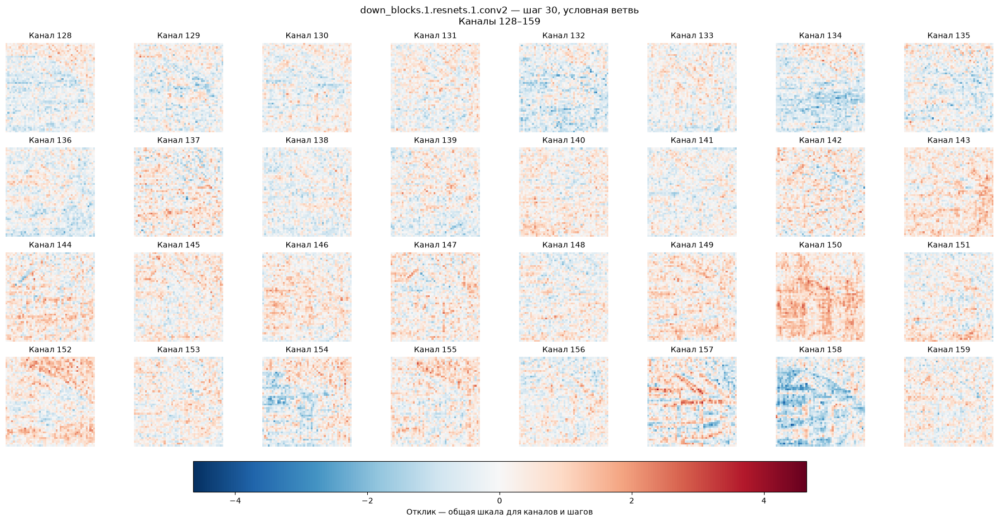

...

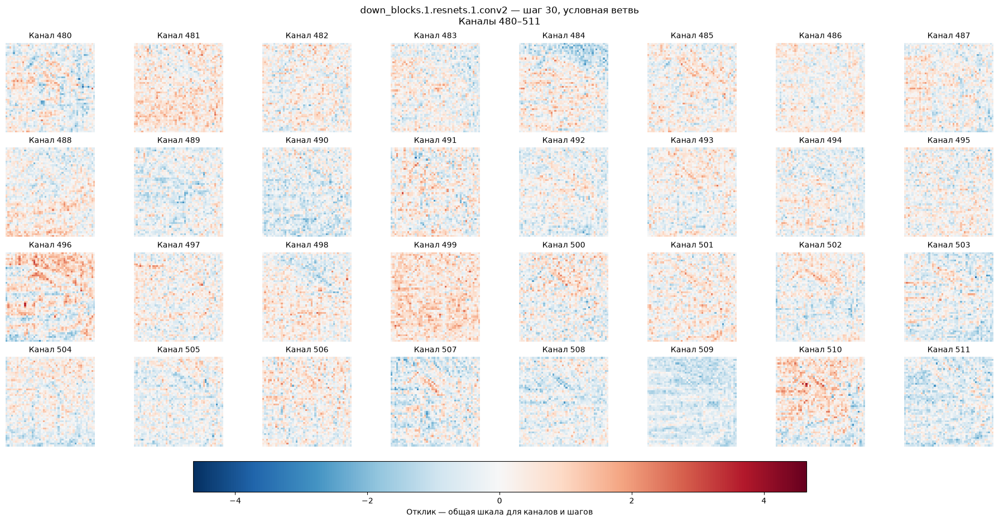

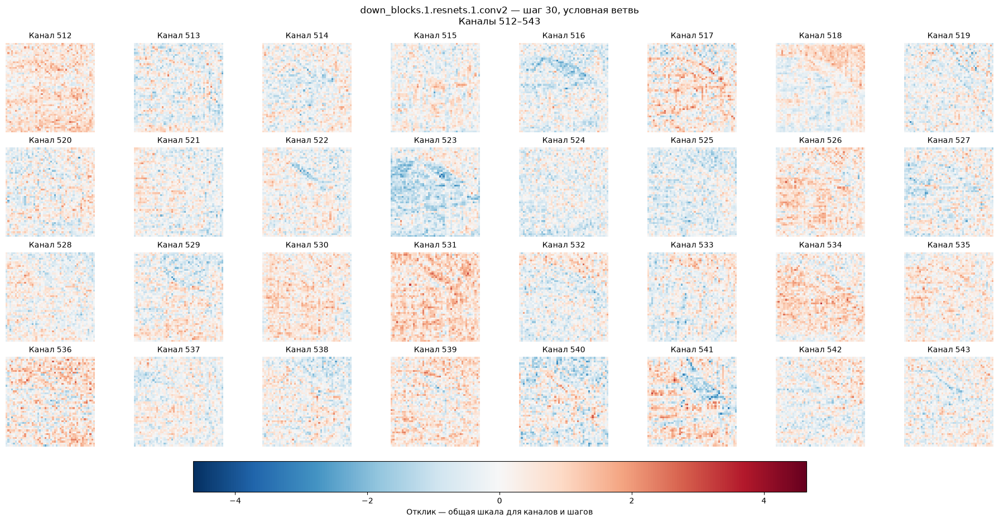

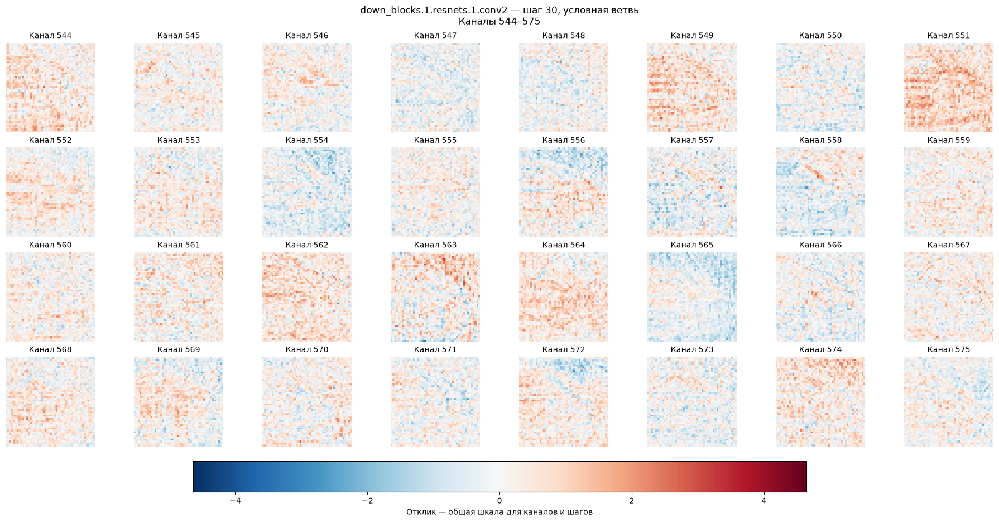

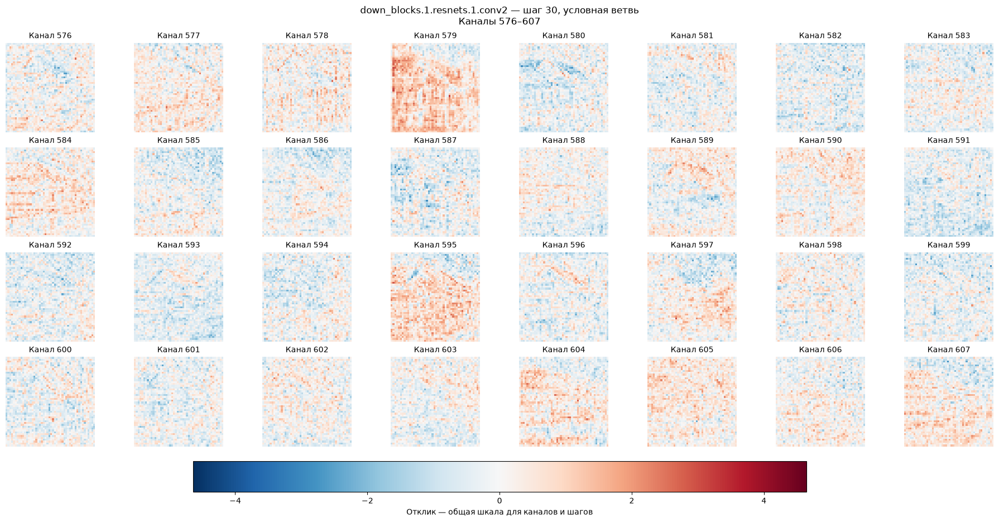

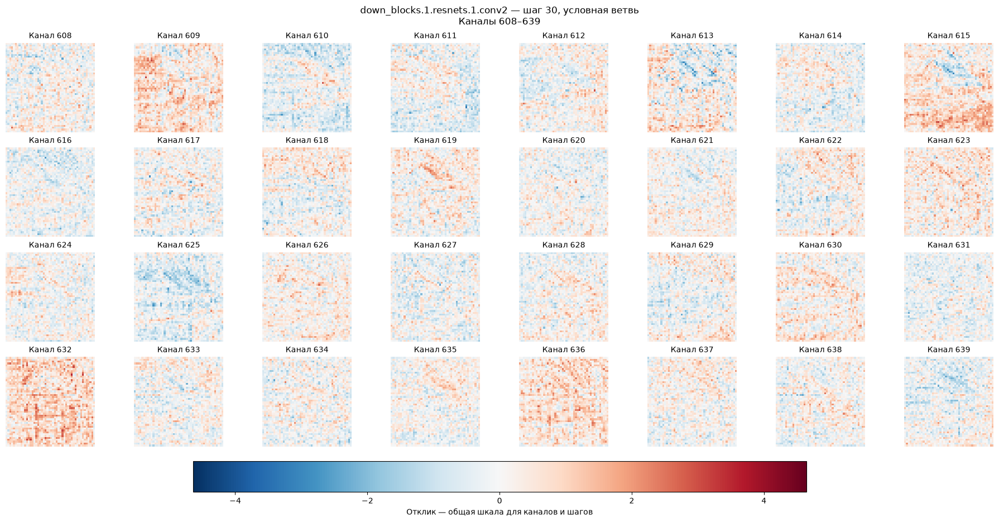

{30: tensor([[[ 2.4988e-01,  4.2285e-01,  1.4258e-01,  ..., -9.7559e-01,
           -1.2183e-01, -6.3184e-01],
          [-7.2998e-02,  1.6846e-02,  7.9224e-02,  ..., -1.1982e+00,
           -1.7188e-01, -5.0488e-01],
          [-6.7078e-02, -6.3477e-01, -3.9355e-01,  ..., -5.2588e-01,
           -5.1562e-01, -1.2861e+00],
          ...,
          [-4.6143e-01, -1.0645e+00, -8.8184e-01,  ...,  4.6143e-01,
            4.0283e-01, -1.2012e-01],
          [-5.9631e-02, -9.0576e-01, -1.5515e-01,  ...,  4.0869e-01,
            2.2607e-01,  3.6774e-02],
          [-5.9912e-01, -5.2832e-01, -5.9131e-01,  ...,  4.8242e-01,
           -5.6982e-01, -9.3848e-01]],
 
         [[-1.1578e-01,  1.7908e-01, -5.1953e-01,  ..., -9.0210e-02,
           -2.6587e-01,  7.7246e-01],
          [ 2.8516e-01, -1.1973e+00, -3.7842e-01,  ..., -2.4353e-01,
           -7.7490e-01,  2.3157e-01],
          [-1.4172e-03,  1.4209e-01, -2.1155e-01,  ..., -9.3750e-01,
            1.5344e-01, -7.9492e-01],
          ...,


In [59]:
get_activations("down_blocks.1.resnets.1.conv2", steps=[30])

### mid_blocks

In [55]:
out_activations = 0
for name, module in pipe.unet.named_modules():
    if name.startswith("mid_block.") and isinstance(module, torch.nn.Conv2d):
        print(
            f"{name}: "
            f"каналы {module.in_channels} → {module.out_channels}, "
            f"ядро {module.kernel_size}"
        )
        out_activations += module.out_channels

print(f"\nПо всем сверткам блока тепловых карт активаций: {out_activations}")

mid_block.resnets.0.conv1: каналы 1280 → 1280, ядро (3, 3)
mid_block.resnets.0.conv2: каналы 1280 → 1280, ядро (3, 3)
mid_block.resnets.1.conv1: каналы 1280 → 1280, ядро (3, 3)
mid_block.resnets.1.conv2: каналы 1280 → 1280, ядро (3, 3)

По всем сверткам блока тепловых карт активаций: 5120


### up_blocks

In [54]:
out_activations = 0
for name, module in pipe.unet.named_modules():
    if name.startswith("up_blocks.") and isinstance(module, torch.nn.Conv2d):
        print(
            f"{name}: "
            f"каналы {module.in_channels} → {module.out_channels}, "
            f"ядро {module.kernel_size}"
        )
        out_activations += module.out_channels

print(f"\nПо всем сверткам блока тепловых карт активаций: {out_activations}")

up_blocks.0.resnets.0.conv1: каналы 2560 → 1280, ядро (3, 3)
up_blocks.0.resnets.0.conv2: каналы 1280 → 1280, ядро (3, 3)
up_blocks.0.resnets.0.conv_shortcut: каналы 2560 → 1280, ядро (1, 1)
up_blocks.0.resnets.1.conv1: каналы 2560 → 1280, ядро (3, 3)
up_blocks.0.resnets.1.conv2: каналы 1280 → 1280, ядро (3, 3)
up_blocks.0.resnets.1.conv_shortcut: каналы 2560 → 1280, ядро (1, 1)
up_blocks.0.resnets.2.conv1: каналы 2560 → 1280, ядро (3, 3)
up_blocks.0.resnets.2.conv2: каналы 1280 → 1280, ядро (3, 3)
up_blocks.0.resnets.2.conv_shortcut: каналы 2560 → 1280, ядро (1, 1)
up_blocks.0.upsamplers.0.conv: каналы 1280 → 1280, ядро (3, 3)
up_blocks.1.resnets.0.conv1: каналы 2560 → 1280, ядро (3, 3)
up_blocks.1.resnets.0.conv2: каналы 1280 → 1280, ядро (3, 3)
up_blocks.1.resnets.0.conv_shortcut: каналы 2560 → 1280, ядро (1, 1)
up_blocks.1.resnets.1.conv1: каналы 2560 → 1280, ядро (3, 3)
up_blocks.1.resnets.1.conv2: каналы 1280 → 1280, ядро (3, 3)
up_blocks.1.resnets.1.conv_shortcut: каналы 2560 → 

up_blocks.2.resnets.1.conv2, шаг 30: форма (640, 48, 48), вызовов модуля: 1


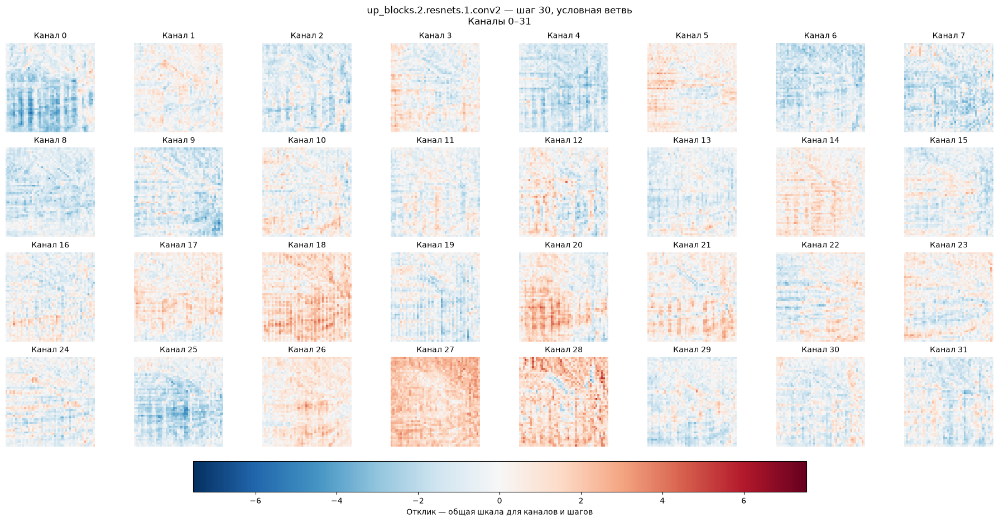

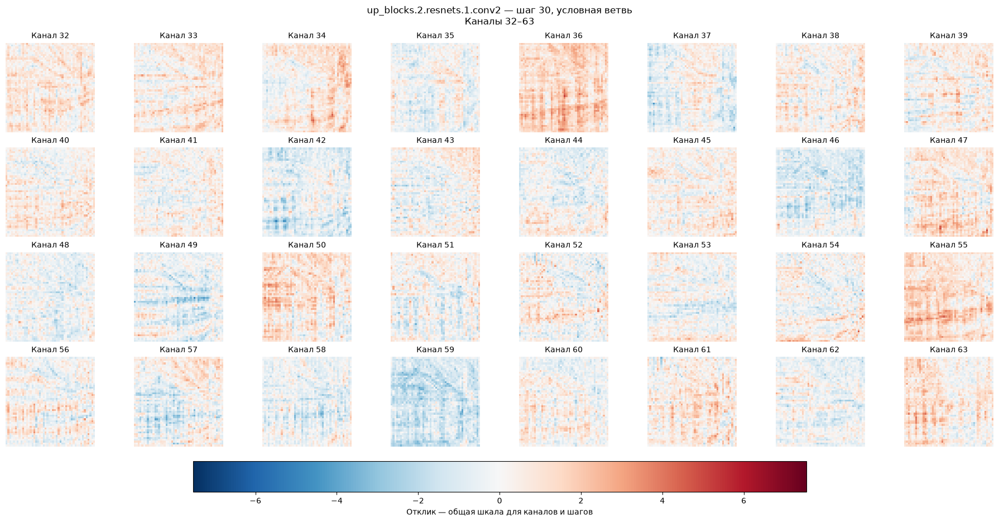

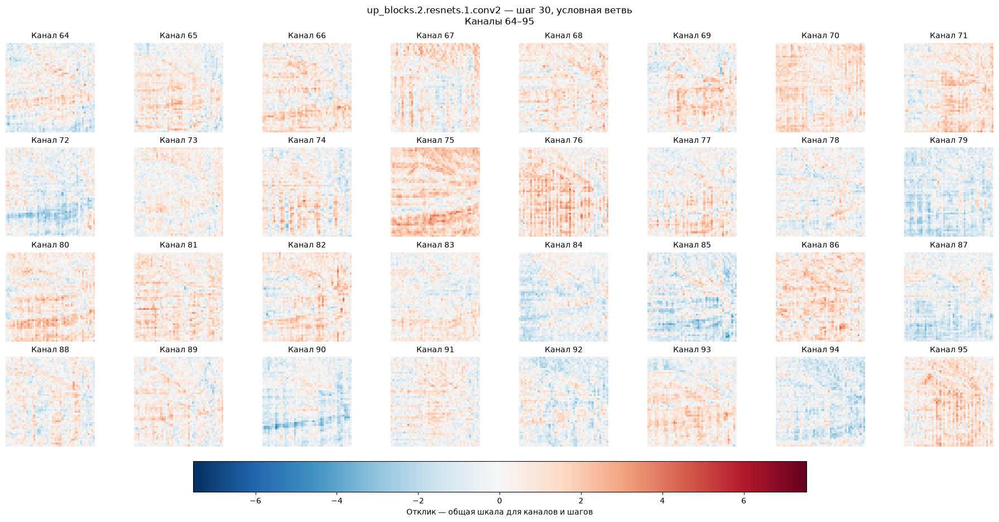

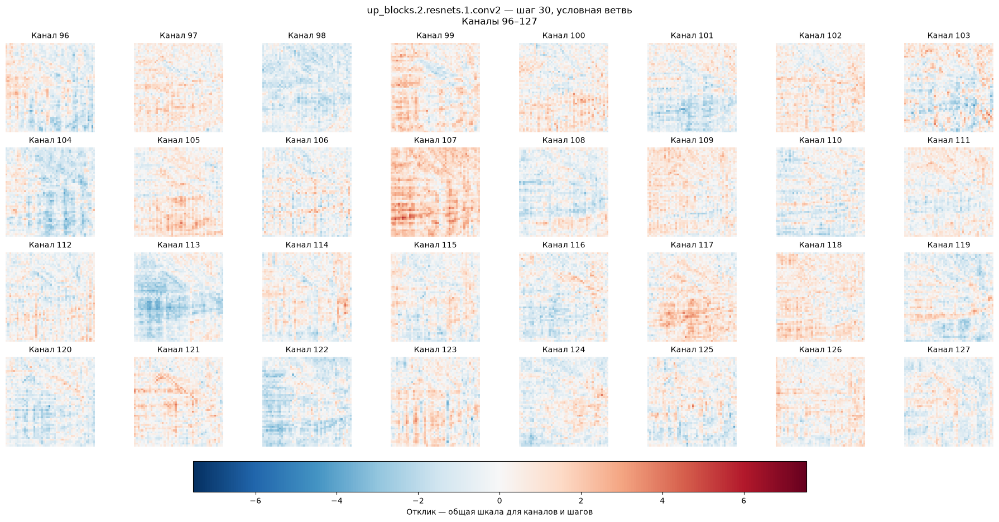

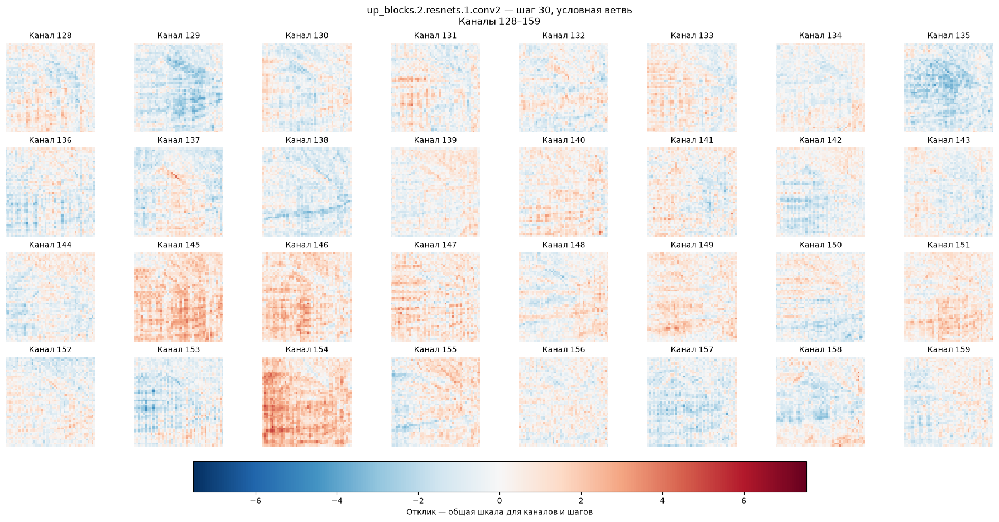

...

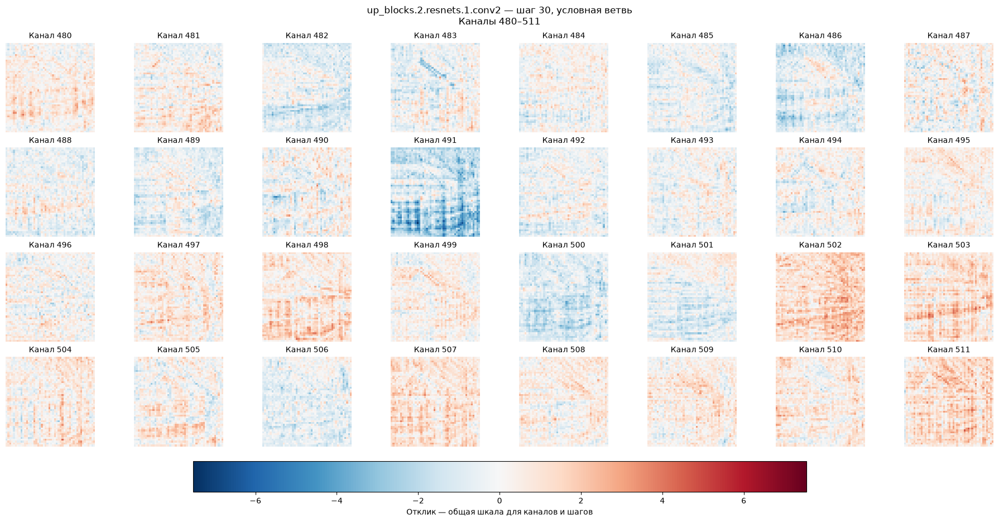

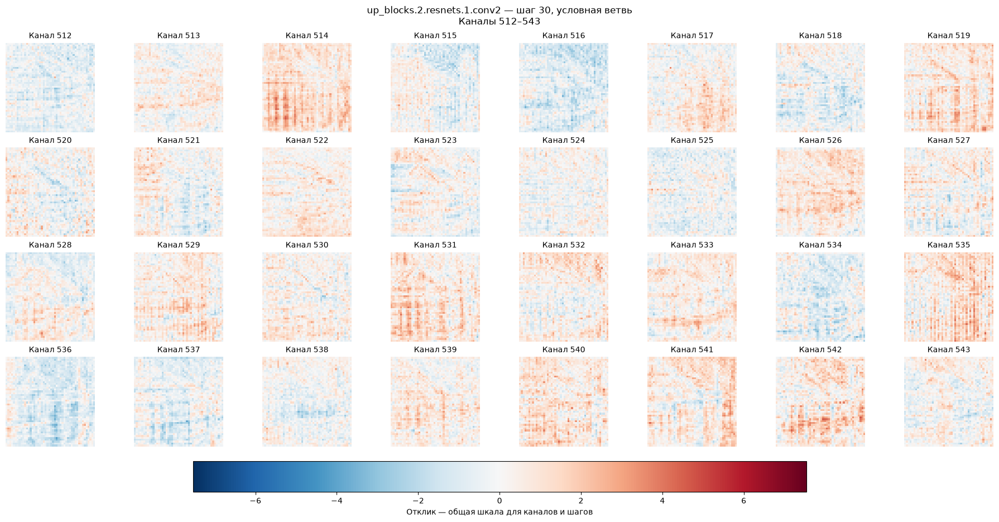

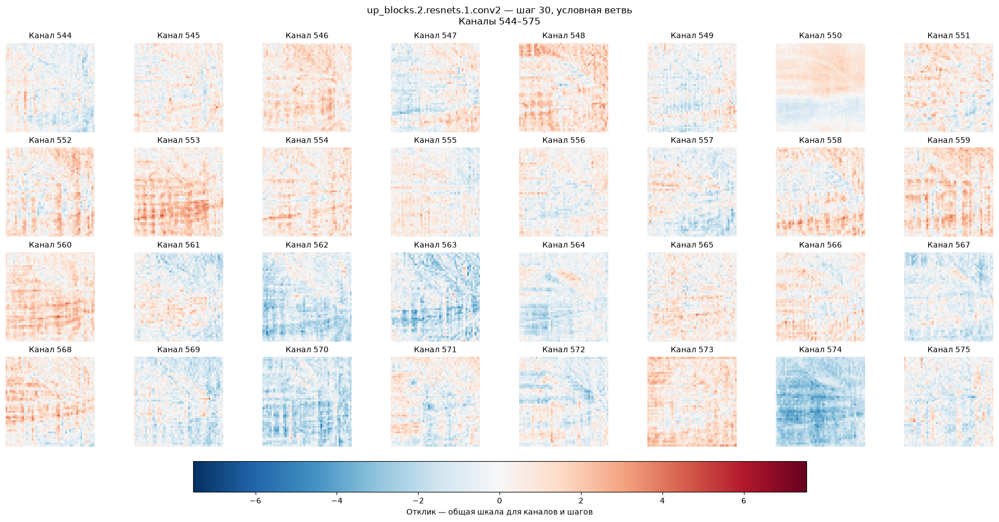

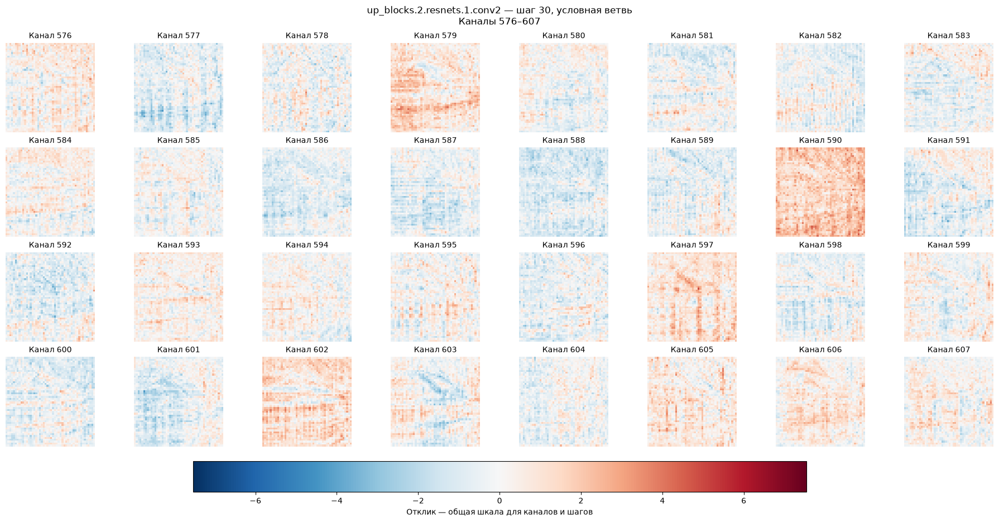

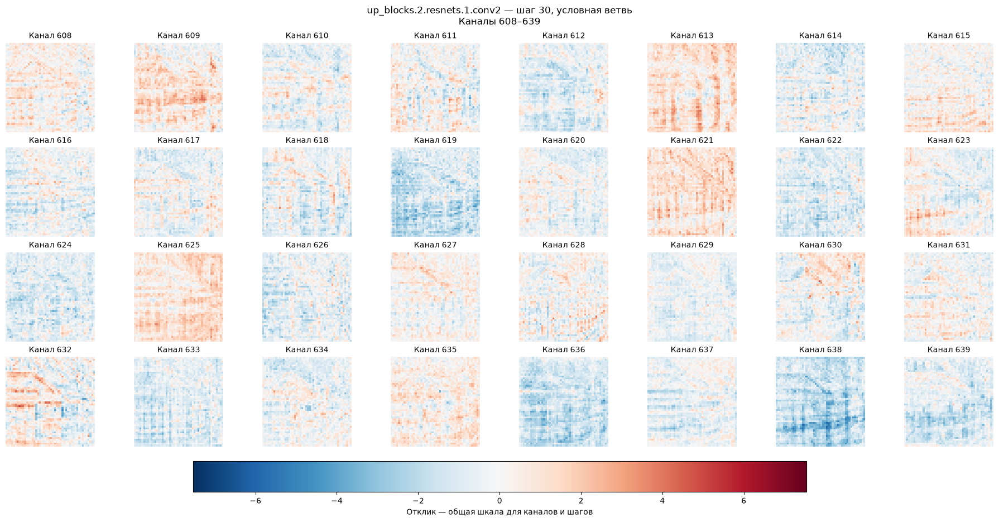

{30: tensor([[[-3.2959e-01, -1.6895e-01, -1.3047e+00,  ..., -4.4312e-01,
           -8.4424e-01, -7.7588e-01],
          [-3.0957e-01, -1.2119e+00, -1.0352e+00,  ..., -5.0879e-01,
           -2.2339e-01, -4.4824e-01],
          [ 1.1787e-03, -1.4429e-01, -1.1006e+00,  ...,  8.5754e-02,
           -8.9795e-01, -1.8005e-01],
          ...,
          [-8.0762e-01, -1.0195e+00, -1.9199e+00,  ..., -2.1082e-01,
           -3.9581e-02, -9.3311e-01],
          [-1.2158e+00, -1.8008e+00, -2.1680e+00,  ...,  7.5500e-02,
           -7.8809e-01, -4.1577e-01],
          [-1.0664e+00, -9.9463e-01, -1.4004e+00,  ..., -7.4707e-01,
           -1.0400e+00, -1.0364e-01]],
 
         [[-1.1494e+00, -4.7046e-01, -6.5186e-01,  ...,  6.7920e-01,
           -4.1943e-01,  9.6680e-02],
          [-3.0176e-01, -3.4009e-01, -4.2407e-01,  ...,  8.1934e-01,
            3.8208e-01,  9.8511e-02],
          [-6.1670e-01, -4.4507e-01, -7.0020e-01,  ...,  1.9128e-01,
            6.4893e-01,  3.4131e-01],
          ...,


In [60]:
get_activations("up_blocks.2.resnets.1.conv2", steps=[30])

### conv_out

In [61]:
out_activations = 0
for name, module in pipe.unet.named_modules():
    if name.startswith("conv_out") and isinstance(module, torch.nn.Conv2d):
        print(
            f"{name}: "
            f"каналы {module.in_channels} → {module.out_channels}, "
            f"ядро {module.kernel_size}"
        )
        out_activations += module.out_channels

print(f"\nПо всем сверткам блока тепловых карт активаций: {out_activations}")

conv_out: каналы 320 → 4, ядро (3, 3)

По всем сверткам блока тепловых карт активаций: 4


conv_out, шаг 30: форма (4, 96, 96), вызовов модуля: 1


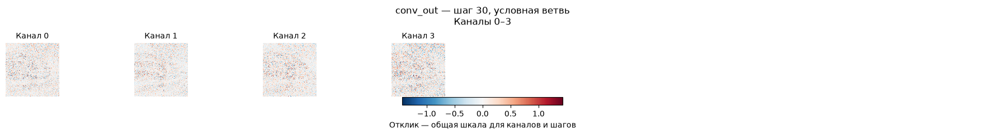

In [64]:
get_activations("conv_out", steps=[30]);

In [65]:
for name, module in pipe.unet.named_modules():
    if name.endswith(".attn2"):
        print(name)

down_blocks.0.attentions.0.transformer_blocks.0.attn2
down_blocks.0.attentions.1.transformer_blocks.0.attn2
down_blocks.1.attentions.0.transformer_blocks.0.attn2
down_blocks.1.attentions.1.transformer_blocks.0.attn2
down_blocks.2.attentions.0.transformer_blocks.0.attn2
down_blocks.2.attentions.1.transformer_blocks.0.attn2
up_blocks.1.attentions.0.transformer_blocks.0.attn2
up_blocks.1.attentions.1.transformer_blocks.0.attn2
up_blocks.1.attentions.2.transformer_blocks.0.attn2
up_blocks.2.attentions.0.transformer_blocks.0.attn2
up_blocks.2.attentions.1.transformer_blocks.0.attn2
up_blocks.2.attentions.2.transformer_blocks.0.attn2
up_blocks.3.attentions.0.transformer_blocks.0.attn2
up_blocks.3.attentions.1.transformer_blocks.0.attn2
up_blocks.3.attentions.2.transformer_blocks.0.attn2
mid_block.attentions.0.transformer_blocks.0.attn2


## Карты внимания

In [66]:
def get_attention_maps(layer_name, step=30):
    """
    Возвращает:
        maps: [число текстовых токенов, H, W],
              cross-attention условной ветви, усреднённый по головам.
        tokens: подписи токенов.

    Для стандартной SD 2.1, без дополнительных адаптеров.
    """
    if not layer_name.endswith(".attn2"):
        raise ValueError("Выберите cross-attention модуль с именем *.attn2.")

    if not isinstance(pipe.scheduler, DDIMScheduler):
        raise ValueError("Этот вариант рассчитан на исходный DDIMScheduler.")

    if step not in trajectory:
        raise ValueError(f"Шаг {step} отсутствует в trajectory.")

    attention = pipe.unet.get_submodule(layer_name)

    # В стандартной SD 2.1 дополнительной нормализации Q/K нет.
    if (
        getattr(attention, "norm_q", None) is not None
        or getattr(attention, "norm_k", None) is not None
    ):
        raise ValueError("Для этого слоя нужно дополнительно учесть нормализацию Q/K.")

    # Вход окружающего Transformer2DModel задаёт пространственную сетку.
    spatial_name = layer_name.split(".transformer_blocks.")[0]
    spatial_module = pipe.unet.get_submodule(spatial_name)

    device = pipe._execution_device
    use_cfg = metadata["guidance_scale"] > 1
    branch_index = 1 if use_cfg else 0

    captured = {}
    handles = []

    def capture_grid(module, inputs):
        x = inputs[0]
        if x.ndim != 4:
            raise ValueError("Ожидался пространственный вход [B, C, H, W].")
        captured["grid"] = tuple(x.shape[-2:])

    def capture_projection(key):
        def hook(module, inputs, output):
            # Сохраняем только условную ветвь.
            captured[key] = (
                output[branch_index:branch_index + 1]
                .detach().float().cpu().clone()
            )
        return hook

    try:
        handles.append(
            spatial_module.register_forward_pre_hook(capture_grid)
        )
        handles.append(
            attention.to_q.register_forward_hook(capture_projection("q"))
        )
        handles.append(
            attention.to_k.register_forward_hook(capture_projection("k"))
        )

        with torch.inference_mode():
            prompt_embeds, negative_prompt_embeds = pipe.encode_prompt(
                prompt=metadata["prompt"],
                negative_prompt=metadata.get("negative_prompt", ""),
                device=device,
                num_images_per_prompt=1,
                do_classifier_free_guidance=use_cfg,
            )

            if use_cfg:
                prompt_embeds = torch.cat(
                    [negative_prompt_embeds, prompt_embeds],
                    dim=0,
                )

            if step == 1:
                z = initial_noise.to(
                    device=device,
                    dtype=pipe.unet.dtype,
                ).clone()
                z = z * pipe.scheduler.init_noise_sigma
            else:
                z = trajectory[step - 1]["latents_after"].to(
                    device=device,
                    dtype=pipe.unet.dtype,
                ).clone()

            t = torch.tensor(
                trajectory[step]["t_from"],
                device=device,
                dtype=torch.long,
            )

            if use_cfg:
                z = torch.cat([z, z], dim=0)

            z = pipe.scheduler.scale_model_input(z, t)

            pipe.unet(
                z,
                t,
                encoder_hidden_states=prompt_embeds,
                return_dict=False,
            )

    finally:
        for handle in handles:
            handle.remove()

        pipe.maybe_free_model_hooks()

    if not {"q", "k", "grid"} <= captured.keys():
        raise RuntimeError("Не удалось получить Q, K и пространственную сетку.")

    # [1, позиции, heads * head_dim] → [heads, позиции, head_dim].
    q = attention.head_to_batch_dim(captured["q"])
    k = attention.head_to_batch_dim(captured["k"])

    # Softmax отдельно для каждой головы, затем усреднение.
    # Расчёт по головам уменьшает пиковое потребление памяти.
    mean_attention = torch.zeros(q.shape[1], k.shape[1])

    for head in range(attention.heads):
        scores = (q[head] @ k[head].T) * attention.scale
        mean_attention += scores.softmax(dim=-1)

    mean_attention /= attention.heads

    h, w = captured["grid"]

    if mean_attention.shape[0] != h * w:
        raise ValueError("Число пространственных токенов не совпало с сеткой.")

    # [H*W, текстовые токены] → [текстовые токены, H, W].
    maps = mean_attention.T.reshape(-1, h, w)

    encoded = pipe.tokenizer(
        metadata["prompt"],
        padding="max_length",
        max_length=pipe.tokenizer.model_max_length,
        truncation=True,
        return_tensors="pt",
    )
    tokens = pipe.tokenizer.convert_ids_to_tokens(
        encoded.input_ids[0].tolist()
    )

    return maps, tokens

In [91]:
def print_maps(layer_name, step):
    
    attention_maps, tokens = get_attention_maps(
        layer_name,
        step,
    )
    
    # Убираем из рисунка служебные токены и padding.
    token_indices = [
        i for i, token in enumerate(tokens)
        if token not in pipe.tokenizer.all_special_tokens
    ]
    
    columns = 6
    rows = (len(token_indices) + columns - 1) // columns
    
    fig, axes = plt.subplots(
        rows,
        columns,
        figsize=(2.5 * columns, 2.5 * rows),
        squeeze=False,
        layout="constrained",
    )
    
    for ax in axes.flat:
        ax.set_axis_off()
    
    limit = max(attention_maps[token_indices].max().item(), 1e-8)
    
    for ax, index in zip(axes.flat, token_indices):
        im = ax.imshow(
            attention_maps[index].numpy(),
            cmap="magma",
            vmin=0,
            vmax=limit,
            interpolation="nearest",
        )
        ax.set_title(f"{index}: {tokens[index]}", fontsize=10)
    
    fig.colorbar(
        im,
        ax=axes.ravel().tolist(),
        shrink=0.7,
        label="Вес cross-attention, среднее по головам",
    )
    
    fig.suptitle(f"{layer_name}\nШаг {step}, условная ветвь")
    plt.show()
    plt.close(fig)

    return 1

In [93]:
attention_layers = [
    name
    for name, module in pipe.unet.named_modules()
    if name.endswith(".attn2")
]

for name in attention_layers:
    print(name)

print("Всего:", len(attention_layers))

down_blocks.0.attentions.0.transformer_blocks.0.attn2
down_blocks.0.attentions.1.transformer_blocks.0.attn2
down_blocks.1.attentions.0.transformer_blocks.0.attn2
down_blocks.1.attentions.1.transformer_blocks.0.attn2
down_blocks.2.attentions.0.transformer_blocks.0.attn2
down_blocks.2.attentions.1.transformer_blocks.0.attn2
up_blocks.1.attentions.0.transformer_blocks.0.attn2
up_blocks.1.attentions.1.transformer_blocks.0.attn2
up_blocks.1.attentions.2.transformer_blocks.0.attn2
up_blocks.2.attentions.0.transformer_blocks.0.attn2
up_blocks.2.attentions.1.transformer_blocks.0.attn2
up_blocks.2.attentions.2.transformer_blocks.0.attn2
up_blocks.3.attentions.0.transformer_blocks.0.attn2
up_blocks.3.attentions.1.transformer_blocks.0.attn2
up_blocks.3.attentions.2.transformer_blocks.0.attn2
mid_block.attentions.0.transformer_blocks.0.attn2
Всего: 16


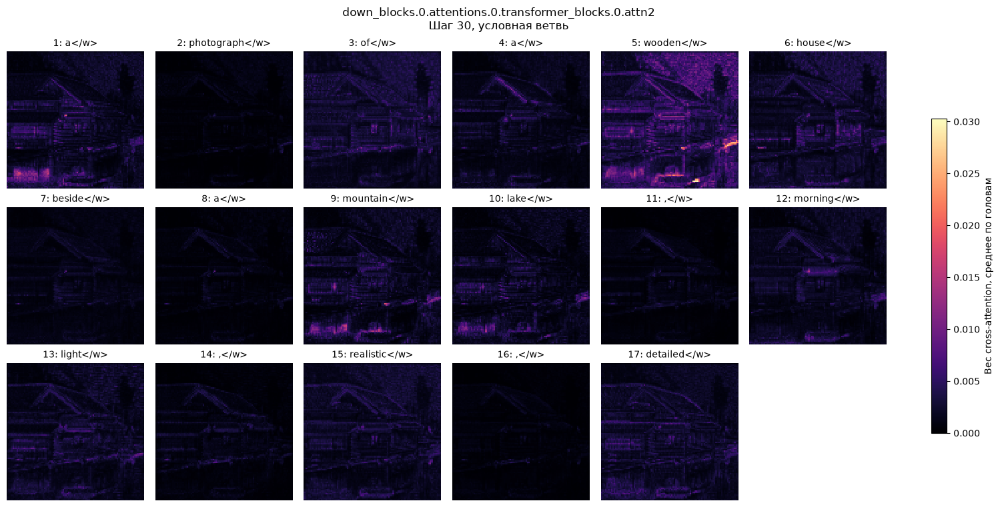

1

In [94]:
print_maps("down_blocks.0.attentions.0.transformer_blocks.0.attn2", 30)

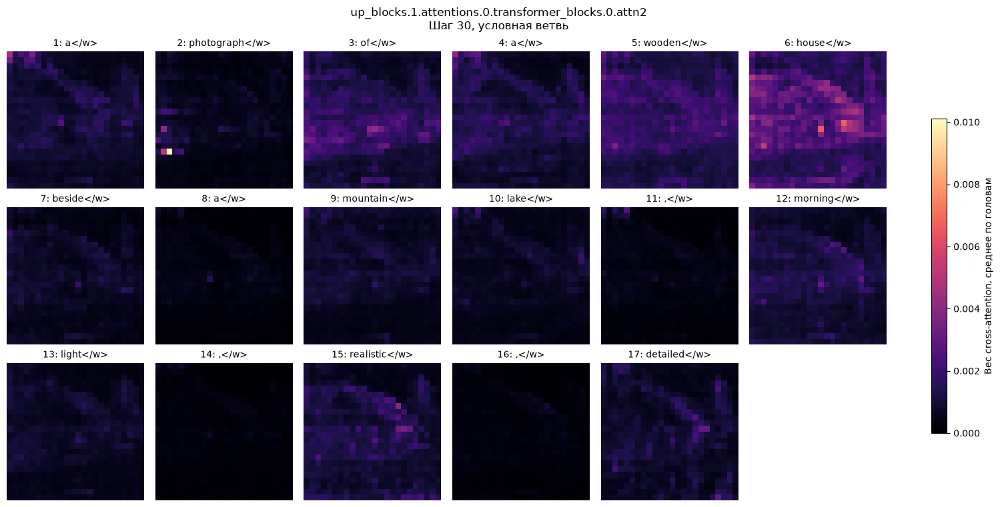

1

In [96]:
print_maps("up_blocks.1.attentions.0.transformer_blocks.0.attn2", 30)

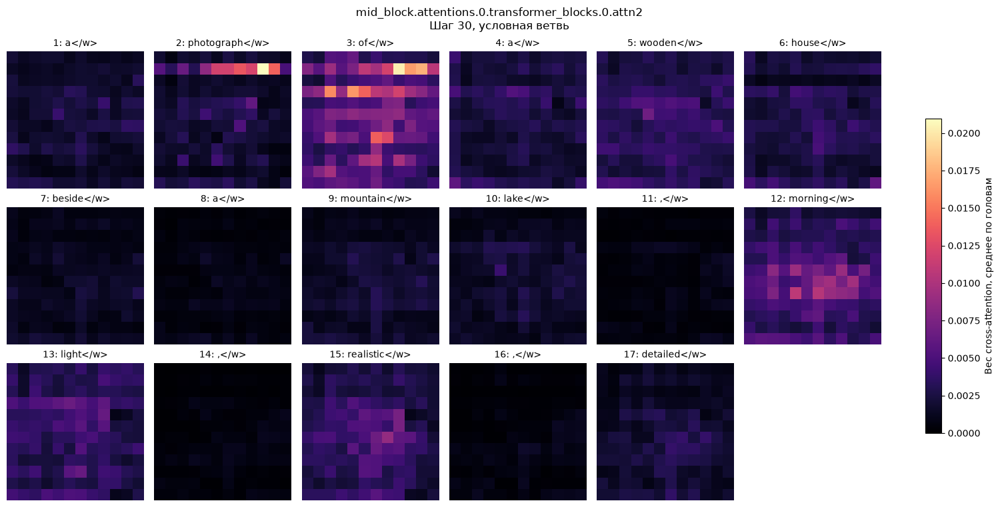

1

In [95]:
print_maps("mid_block.attentions.0.transformer_blocks.0.attn2", 30)

  0%|          | 0/30 [00:00<?, ?it/s]

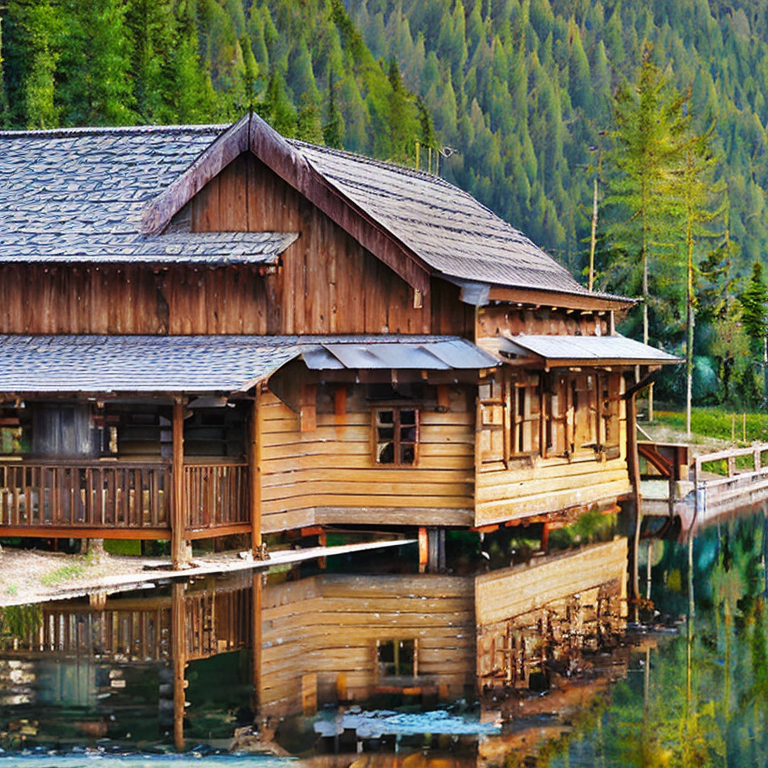

Латентных состояний: 30
Снимков выбранного слоя: 6
Модулей с пространственными выходами: 172


In [109]:
# Ослабить в два раза выход cross-attention слоя внимания down_blocks.1.attentions.0.transformer_blocks.0.attn2

def weaken_attention(module, inputs, output):
    modified = output.clone()
    modified[1] *= 0.5
    return modified


experiment = run_experiment(
    pipe,
    hooks={
        "down_blocks.0.attentions.0.transformer_blocks.0.attn2":
            weaken_attention,
    },
)

  0%|          | 0/30 [00:00<?, ?it/s]

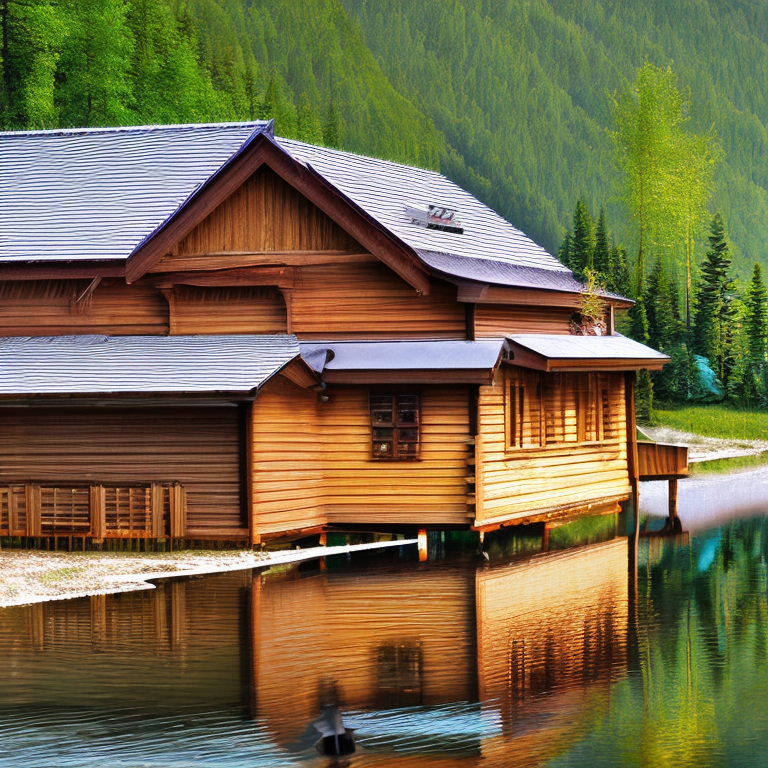

Латентных состояний: 30
Снимков выбранного слоя: 6
Модулей с пространственными выходами: 172


In [102]:
# обнулить каналы [0, 5, 12] свертки в слое down_blocks.0.resnets.0.conv2

def zero_channels(module, inputs, output):
    modified = output.clone()
    modified[1, [0, 5, 12], :, :] = 0
    return modified


experiment = run_experiment(
    pipe,
    hooks={
        "down_blocks.0.resnets.0.conv2": zero_channels,
    },
)

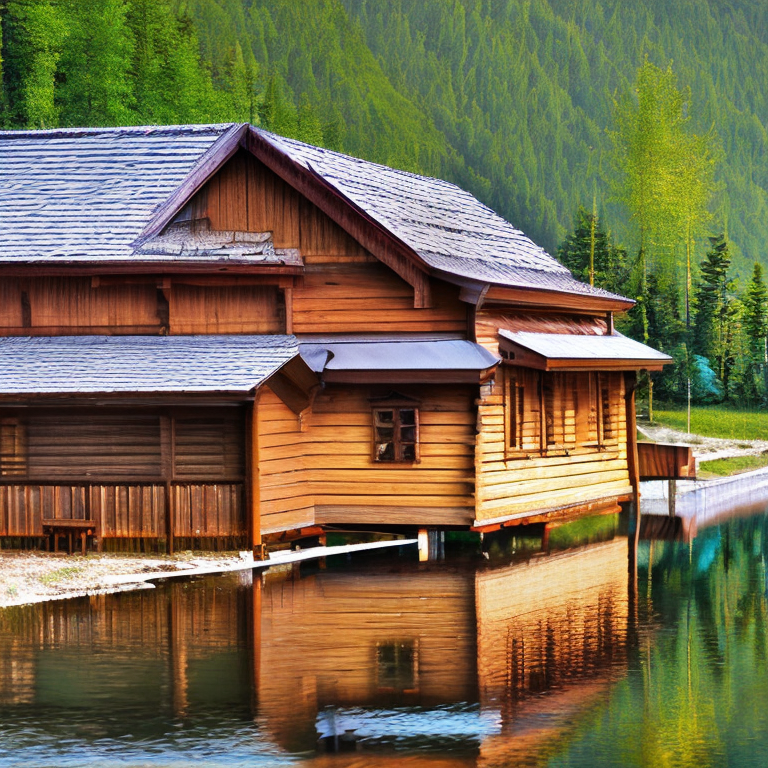

In [110]:
# Было так
display(result.images[0])